# Week 5: Ensemble Classification

# First time here?



1.   Copy this file to your Google Drive so you can edit it: **File->Save a copy in Drive** (requires a personal Google account)
2.   Done? Consider giving your copy a better name (e.g., including your name and/or student ID) - just click on the filename in the top left and edit it.
3.   (Want to re-open your copy in future? Go: **File->Open notebook** and select the Google Drive tab)
4.   (Want to find your file on your Google Drive? Google puts Colab files in a folder called "Colab Notebooks")

# Our implementations

In this notebook we're going to focus on understanding some very simple Python implementations of different ensemble classifiers.

It should be useful for checking your understanding from your research this week, and it may also be useful to return to and extend in future.

## `MyVotingClassifier`

Below is a really simple NumPy implementation of a voting ensemble classifier. We'll take some time to look at it in detail in a moment, but for now let's just run it and see how it performs.

Click the play button on the code cell to define the class, and then scroll down to the next text cell and keep reading:

In [1]:
import numpy as np

class MyVotingClassifier:

  # The class constructor
  def __init__(self, models):
    # store a copy of the model objects we've been handed
    self.models = models

    # how many were there
    self.n_models = len(models)

  # The method we call to fit the model to training data
  def fit(self, train_examples, train_labels):

    # what are the unique labels in this problem
    self.labels = np.unique(train_labels)

    # how many are there
    self.n_labels = self.labels.shape[0]

    # loop over the models we've been supplied, and train them on the training data
    for i in range(self.n_models):
      self.models[i].fit(train_examples, train_labels)

  # The method we call to generate predictions for a batch of testing examples (the same as previous labs)
  def predict(self, test_examples):

    # how many test examples are there
    n_test_examples = test_examples.shape[0]

    # make numpy array the right size to store our predicted labels
    predicted_labels = np.empty(n_test_examples, dtype=self.labels.dtype)

    # loop over all the testing examples that were passed to us
    for i in range(n_test_examples):

        # For this one testing example... (note we're careful to keep it 2D this time, so we can use sklearn models)
        this_example = test_examples[i:i+1,:]

        # generate a prediction and store it
        predicted_labels[i] = self.predict_one(this_example)

    # return all the predictions
    return predicted_labels

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):


# Create an empty array to store predictions from each model
    labels = np.empty(self.n_models, dtype=self.labels.dtype)

    # Loop through each model in the ensemble
    for i in range(self.n_models):
  # Get the prediction from the i-th model for this example
  # [0] is used because predict() returns an array, so we take the first value
      labels[i] = self.models[i].predict(this_example)[0]

# Find all unique predicted labels and count how many times each appears
    unique_labels, counts = np.unique(labels, return_counts=True)

# Find the index of the label with the highest count (majority vote)
    max_count_index = np.argmax(counts)

# Select the label that appears most frequently
    prediction = unique_labels[max_count_index]

# Return the final prediction (majority vote result)
    return prediction


## Basic supervised learning recipe

The code below shows our basic supervised learning recipe again. We're using it to train and evaluate on the iris.csv dataset again, but this time we're using the basic voting ensemble implementation we defined above. It would be great to use the individual `My*` model implementations we've made in the previous weeks, but if we paste all the class definitions into this notebook it will get huge - so for now we work with the Scikit-learn implementations. (There's a chance for you to swap them out later.)

*   How accurate is the model? ** 95 %**

Accuracy: 0.95 (or 95.0 %)


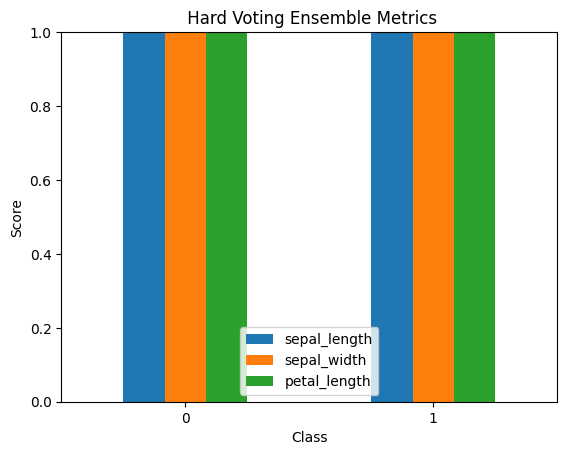

In [8]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/iris.csv')

# Set the name of the target feature
target_feature = 'species'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# Create one of each of the different models we've met so far
models = [KNeighborsClassifier(), GaussianNB(), DecisionTreeClassifier(random_state=99)]

# Use them to create a voting ensemble
model = MyVotingClassifier(models)
#model = MyVotingClassifierV2(models)

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")

import matplotlib.pyplot as plt

# Plot selected metrics (first 2 rows, first 3 columns) as a bar chart
observations.iloc[0:2, 0:3].plot(kind='bar')

# Add a title to the graph
plt.title(" Hard Voting Ensemble Metrics")

# Label the y-axis (scores like accuracy/precision/etc.)
plt.ylabel("Score")

# Label the x-axis (classes or categories)
plt.xlabel("Class")

# Set y-axis limits between 0 and 1 (since scores are proportions)
plt.ylim(0, 1)

# Keep x-axis labels horizontal for readability
plt.xticks(rotation=0)

# Display the plot
plt.show()

# Review

Now take some time to have a careful look through the `MyVotingClassifier` class. Can you match each of the stages up with your research from this week? It's worth spending time on this task - you want to ensure you understand the model fully:

*    **Add descriptive comments where they are missing in the code**

**Tip**: consider adding print statements to `MyVotingClassifier` to help you understand what's happening. Re-run the code cell that defines the class before re-running the recipe code to see the output. Remember about printing things like `.shape` as well as printing out the raw contents of arrays (which can produce many lines of output).

## Soft voting

In our initial implementation, we used "hard voting", where each model's prediction has the same importance (equivalent to calculating the mode/most common value of their predicted labels). Below we extend the original class to also allow for "soft voting" (based on the label probabilities generated by each model). We'll take some time to look at it in detail in a moment, but for now let's just run it and see how it performs.

Click the play button on the code cell to define the class, and then update the recipe code above to see what accuracy it gives:

**Tip**: it would be nice if it happened to give a little performance boost for the iris data, but it doesn't make any difference - you should see the same accuracy again. (Just make sure you're definitely calling the _new_ class - `MyVotingClassifierV2`.)

**Tip**: Remember voting (or any kind of ensemble) isn't a _guarantee_ of improved performance. For any particular data / hold out split / random seed it could even potentially give lower performance. (It's a good thing _on average_.)

In [3]:
class MyVotingClassifierV2(MyVotingClassifier):

  # The class constructor
  def __init__(self, models, voting='soft'):
    super().__init__(models)   # call parent constructor

    # store the voting approach (hard/soft)
    self.voting = voting

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):

    if self.voting == 'hard':
      # the is the same code we used in the original voting class
      labels = np.empty(self.n_models, dtype=self.labels.dtype)

      for i in range(self.n_models):
        labels[i] = self.models[i].predict(this_example)[0]

      unique_labels, counts = np.unique(labels, return_counts=True)
      max_count_index = np.argmax(counts)
      prediction = unique_labels[max_count_index]

    elif self.voting == 'soft':

      # Create an array to store summed probabilities for each label
      probabilities = np.zeros(self.n_labels)

      # Loop through each model
      for i in range(self.n_models):
        # Add the predicted probabilities from each model
        # predict_proba() gives probabilities for each class
        # [0] is used because the result is inside an array
        probabilities += self.models[i].predict_proba(this_example)[0]

      # Find the index of the label with the highest total probability
      max_count_index = np.argmax(probabilities)

      # Select the label corresponding to the highest probability
      prediction = self.labels[max_count_index]

    # Return the final prediction
    return prediction



# Review

Now take some time to have a careful look through the `MyVotingClassifierV2` class. Can you match up the new `predict_one()` method with your research from this week? Spend some time to ensure you understand the method fully:

*    **Add descriptive comments where they are missing in the code**

**Tip**: consider adding print statements to `MyVotingClassifierV2` to help you understand what's happening. Re-run the code cell that defines the class before re-running the recipe code to see the output. Remember about printing things like `.shape` as well as printing out the raw contents of arrays (which can produce many lines of output).

## `MyBaggingClassifier`

Below is a really simple NumPy implementation of a bagging (bootstrap aggregating) ensemble classifier. We'll take some time to look at it in detail in a moment, but for now let's just run it and see how it performs.

Click the play button on the code cell to define the class, and then scroll down to the next text cell and keep reading:

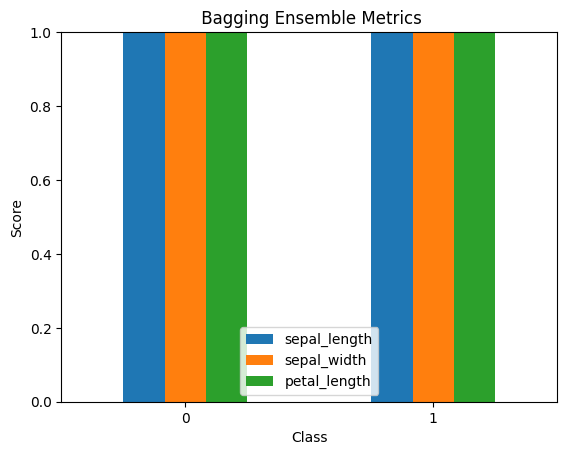

In [11]:
import numpy as np
import copy

class MyBaggingClassifier:

  # The class constructor
  def __init__(self, base_model, n_models=5, random_state=None):

    # store a copy of the base model we've been handed
    self.base_model = base_model

    # how many copies are requested
    self.n_models = n_models

    # re-seed the random number generator if a value was supplied:
    self.rng = np.random.default_rng(random_state)

  # The method we call to fit the model to training data
  def fit(self, train_examples, train_labels):

    # what are the unique labels in this problem
    self.labels = np.unique(train_labels)

    # how many training examples do we have to sample from
    self.n_examples = train_examples.shape[0]

    # how many samples will we draw for each model (note - as long as we're using replacement we only tend to include ~64% of the training data)
    self.n_samples = self.n_examples

    # get ready to store our models (we shouldn't use numpy arrays for this kind of thing - it's for numeric data)
    self.models = []

    # train all the requested models on different samples of the training data
    for i in range(self.n_models):

      # grab a copy of the base model - notice we need a deep copy to avoid lots of references to a single model
      this_model = copy.deepcopy(self.base_model)

      #
      sample_indices = self.rng.choice(self.n_examples, size=self.n_samples, replace=True)

      #
      this_model.fit(train_examples[sample_indices, :], train_labels[sample_indices])

      #
      self.models.append(this_model)

  # The method we call to generate predictions for a batch of testing examples (the same as previous labs)
  def predict(self, test_examples):

    # how many test examples are there
    n_test_examples = test_examples.shape[0]

    # make numpy array the right size to store our predicted labels
    predicted_labels = np.empty(n_test_examples, dtype=self.labels.dtype)

    # loop over all the testing examples that were passed to us
    for i in range(n_test_examples):

        # For this one testing example... (note we're careful to keep it 2D this time, so we can use sklearn models)
        this_example = test_examples[i:i+1,:]

        # generate a prediction and store it
        predicted_labels[i] = self.predict_one(this_example)

    # return all the predictions
    return predicted_labels

  # A method to generate a prediction for a single example
  def predict_one(self, this_example):

    # the is the same code we used in the original voting class
    labels = np.empty(self.n_models, dtype=self.labels.dtype)

    for i in range(self.n_models):
      labels[i] = self.models[i].predict(this_example)[0]

    unique_labels, counts = np.unique(labels, return_counts=True)
    max_count_index = np.argmax(counts)
    prediction = unique_labels[max_count_index]

    return prediction

    # Plot (same style as before)
observations.iloc[0:2, 0:3].plot(kind='bar')

plt.title(" Bagging Ensemble Metrics")
plt.ylabel("Score")
plt.xlabel("Class")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.show()


## Basic supervised learning recipe

The code below shows our basic supervised learning recipe again. But this time we're using the basic bagging ensemble implementation we defined above. It would be great to use the individual `MyKnnClassfier` model implementation we made in the previous weeks, but again to keep the notebook from getting huge we'll just use the Scikit-learn implementation. (There's a chance for you to swap them out later.)

*   How accurate is the model? ** 96.7 %**

**Tip**: this time you should see a little improvement in accuracy for the iris data.

**Tip**: Remember bagging (or any kind of ensemble) isn't a _guarantee_ of improved performance. For any particular data / hold out split / random seed it could even potentially give lower performance. (It's a good thing _on average_.)

Accuracy: 0.9666666666666667 (or 96.7 %)


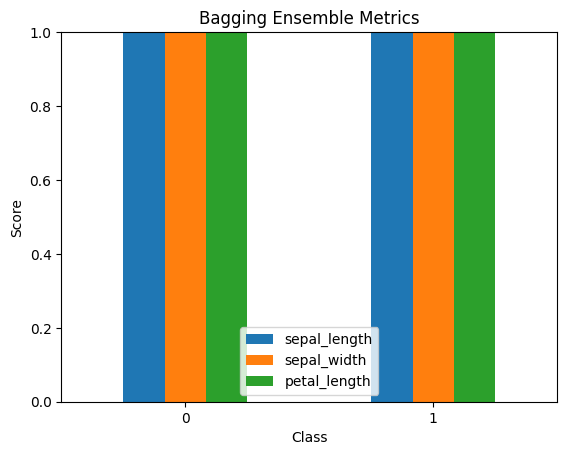

In [7]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/iris.csv')

# Set the name of the target feature
target_feature = 'species'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing labels ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_labels = observations_test[target_feature].to_numpy()

# Split into training examples and training labels ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_labels = observations_train[target_feature].to_numpy()

# What model will we use in this ensemble
base_model = KNeighborsClassifier();

# Use it to create a bagging ensemble
model = MyBaggingClassifier(base_model, n_models=10, random_state=99)

# Call the model's fitting/training algorithm, passing in our training examples and training labels
model.fit(train_examples, train_labels)

# Use the trained model to generate predictions based on our testing examples
predictions = model.predict(test_examples)

# Find the total number of model predictions that matched with their corresponding testing labels
correct_predictions = sum(predictions == test_labels)
# Calculate the model's accuracy: the fraction of predictions that were correct
accuracy = correct_predictions / len(test_labels)
# Display the accuracy as a single quantitative measure of overall performance
print("Accuracy:", accuracy, "(or", round(accuracy*100, 1), "%)")


import matplotlib.pyplot as plt

# Plot selected metrics (first 2 rows, first 3 columns) as a bar chart
observations.iloc[0:2, 0:3].plot(kind='bar')

# Add a title to the graph
plt.title("Bagging Ensemble Metrics")

# Label the y-axis (scores like accuracy/precision/etc.)
plt.ylabel("Score")

# Label the x-axis (classes or categories)
plt.xlabel("Class")

# Set y-axis limits between 0 and 1 (since scores are proportions)
plt.ylim(0, 1)

# Keep x-axis labels horizontal for readability
plt.xticks(rotation=0)

# Display the plot
plt.show()


# Review

Now take some time to have a careful look through the `MyBaggingClassifier` class. Can you match each of the stages up with your research from this week? It's worth spending time on this task - you want to ensure you understand the model fully:

*    **Add descriptive comments where they are missing in the code**

**Tip**: consider adding print statements to `MyBaggingClassifier` to help you understand what's happening. Re-run the code cell that defines the class before re-running the recipe code to see the output. Remember about printing things like `.shape` as well as printing out the raw contents of arrays (which can produce many lines of output).

# Next steps

You could, if you wanted to, add more code to any of the classes in this notebook in order to gain further insight into the workings of the various models' `fit()` and `predict()` methods. For example, see how we use the Matplotlib package for visualisation in the second notebook. There's also the potential to go a good deal further if you're interested/being ambitious on 1CWK50; below are some suggestions.

*   **Have a careful read over ALL the following suggestion before jumping into any of them. Be strategic - what aspects of ensembles are interesting to you? Do you want to develop particular bits of understanding/visualisation code to help you aim for a higher score on 1CWK50? Do you just like a coding challenge? (Note that some of the tasks are connected.)**

1.   Extend `MyBaggingClassifier` so that the constructor supports a `pasting=True` option (randomly sampling the training examples/labels _without_ replacement)
2.   Extend `MyBaggingClassifier` to support random subspaces (randomly sampling predictive features _without_ replacement) and random patches (random subspaces at the same time as randomly sampling the training example/labels)
3.   Copy the `My*` implementations you've worked on in previous weeks into this notebook, and switch the voting ensemble (V1) over to use them instead
4.   Extend your copies of the `My*` implementations (see previous challenge) so that each one has a `predict_proba()` method - check they now also work with the V2 soft voting ensemble. (Optionally: Extend the V2 soft voting ensemble to include a `predict_proba()` method of its own.)
5.   Extend your `MyDecisionTree` implementation so that it is ready for use within a random forest implementation
     *   It will need to offer a constructor option to allow random sampling of the predictive features _without_ replacement _at every split attempt_ (by default, leave it sampling _all_ predictive features for normal DT behaviour)
     *   Get it handling ties a bit better by looping over the predictive features in a random order _at every split attempt_ (imperfect, but practical and similar to the Scikit-learn approach)
     *   **Tip** NumPy's `rng.choice()` function is ideal for doing both these things - see also how it's used in the existing `MyBaggingClassifier` implementation above
     *   **Tip** add `random_state` support for repeatability by following the example in `MyBaggingClassifier` (see the constructor)
6.   Make yourself a `MyRandomForestClassifier` class, that builds a Python list of models from your updated `MyDecisionTreeClassifier` class (see previous challenge)
     *   The `MyBaggingClassifier` class provides a nice starting point
     *   Make sure you are using the new functionality you added to your updated decision tree class to randomly sample predictive features _per split attempt_ (**note**: this is different from doing random subspaces)
     *   Allow the final prediction to be generated using soft voting
7. Extend your `MyNaiveBayesClassifier` class to support an interesting hyperparameter that Scikit-learn doesn't support. Rather than using Normal/Gaussian distributions to model the likelihood for each feature value, can you allow for the use of [kernel density estimation](https://scikit-learn.org/stable/modules/density.html#kernel-density-estimation) which tries to represent the local density of a 1D distribution using a smooth curve. Use scikit-learn's [`KernelDensity`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KernelDensity.html) class to add support via an argument to your class constructor.
8. Extend your `MyKNeighborsClassifier` class to support the use of inverse distance weighting when calculating predictions from the nearest neighbours. Have a look at/play with the `weights=distance` option in Scikit-learn's [`KNeighborsClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) implementation for guidance.

